# Solutions to notebook 5: Chebyshev differentiation matrices

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/05_chebyshev_differentiation_matrices.ipynb)

Worked solutions to the exercises at the end of [notebook 5](../notebooks/05_chebyshev_differentiation_matrices.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def scale_cheb(N, a, b):
    """Chebyshev matrix and points mapped from [-1, 1] to [a, b] (x runs from b down to a)."""
    D, x = cheb(N)
    return D * 2 / (b - a), a + (b - a) * (x + 1) / 2

## Exercise 1

Compute `cheb(2)` by hand from the formula of 5.2 and check it against the function. Then
confirm numerically that $D^{N+1}$ is zero to rounding for $N = 5$ (entries of order
$10^{-11}$), and explain why this must be so.

For $N = 2$ the points are $x = 1, 0, -1$ and $c = (2, 1, 2)$. The off-diagonal entries are
$D_{ij} = \dfrac{c_i}{c_j}\dfrac{(-1)^{i+j}}{x_i - x_j}$:

$$D_{01} = \frac21\cdot\frac{-1}{1 - 0} = -2,\quad D_{02} = \frac22\cdot\frac{1}{1 + 1} = \frac12,\quad
D_{10} = \frac12\cdot\frac{-1}{0 - 1} = \frac12,\quad D_{12} = \frac12\cdot\frac{-1}{0 + 1} = -\frac12,$$

and likewise $D_{20} = -\tfrac12$, $D_{21} = 2$. The diagonal makes each row sum to zero:
$D_{00} = \tfrac32$, $D_{11} = 0$, $D_{22} = -\tfrac32$. The corner entry agrees with
$(2N^2 + 1)/6 = \tfrac96$. These are the three-point difference formulas of 5.1 with $h = 1$,
written with the points in decreasing order.

In [3]:
by_hand = np.array([[ 3 / 2, -2,  1 / 2],
                    [ 1 / 2,  0, -1 / 2],
                    [-1 / 2,  2, -3 / 2]])
D2pt, x2pt = cheb(2)
print("cheb(2):\n", D2pt)

N = 5
D, x = cheb(N)
powers = [np.abs(np.linalg.matrix_power(D, k)).max() for k in range(1, N + 2)]
print(f"\nN = {N}: largest entry of D^k for k = 1, ..., {N + 1}:")
print("  ".join(f"{p:.3g}" for p in powers))
print("D^5 applied to x^5:", np.round(np.linalg.matrix_power(D, 5) @ x**5, 8))

cheb(2):
 [[ 1.5 -2.   0.5]
 [ 0.5  0.  -0.5]
 [-0.5  2.  -1.5]]

N = 5: largest entry of D^k for k = 1, ..., 6:
10.5  68.4  233  446  384  2.34e-11
D^5 applied to x^5: [120. 120. 120. 120. 120. 120.]


In [4]:
# verify: cheb(2) against the entries worked out by hand; D^6 is zero to rounding level, where D^5 is not;
# and the fifth derivative of x^5 is 5! = 120 at every point
assert np.allclose(D2pt, by_hand, atol=1e-15)
assert powers[N] < 1e-9 * powers[N - 1] and powers[N - 1] > 100
assert np.allclose(np.linalg.matrix_power(D, 5) @ x**5, 120.0, rtol=1e-9)

**Answer.** `cheb(2)` returns the matrix worked out by hand, with rows
$(\tfrac32, -2, \tfrac12)$, $(\tfrac12, 0, -\tfrac12)$ and $(-\tfrac12, 2, -\tfrac32)$. For
$N = 5$ the largest entry of $D^5$ is 384 and that of $D^6$ is $2\times10^{-11}$, which is zero
up to rounding. It must be zero: $D^{N+1}\mathbf{u}$ holds the values of the $(N+1)$-th
derivative of the interpolant of $\mathbf{u}$, the interpolant is a polynomial of degree at most
$N$, and $N + 1$ differentiations reduce any such polynomial to zero. The power $D^N$ is not
zero, because the $N$-th derivative of $x^N$ is $N!$ (here $5! = 120$). A matrix with a
vanishing power is called nilpotent, and all its eigenvalues are zero.

## Exercise 2

The velocity profile of laminar flow of a power-law fluid in a channel is
$u(y) = 1 - |y|^{(n+1)/n}$ for $-1 \le y \le 1$. Estimate the wall shear rate $-u'(1)$ with
`cheb` for $n = 1$, $n = 1/2$ and $n = 0.7$, using $N = 8, 16, 32, 64$. Which cases converge
spectrally, which do not, and why?

The exact wall shear rate is $-u'(1) = (n+1)/n$: 2, 3 and 2.4286. In the code the wall $y = 1$
is index 0. What decides the convergence is the smoothness of $|y|^{p}$, $p = (n+1)/n$, at the
centre of the channel, not at the wall. For $n = 1$ the profile is the parabola $1 - y^2$. For
$n = 1/2$ it is $1 - |y|^3$, whose third derivative jumps at $y = 0$. For $n = 0.7$ the
exponent is $p = 2.43$ and already the third derivative is unbounded at $y = 0$.

   n     exact      N = 8      N = 16     N = 32     N = 64     order
  1.0   2.0000    0.0e+00    1.8e-15    1.4e-14    0.0e+00    exact
  0.5   3.0000    2.7e-02    3.7e-03    4.7e-04    5.9e-05     2.99
  0.7   2.4286    2.9e-02    5.8e-03    1.1e-03    2.1e-04     2.42
n = 0.5 on the half channel with N = 8: error 0.0e+00


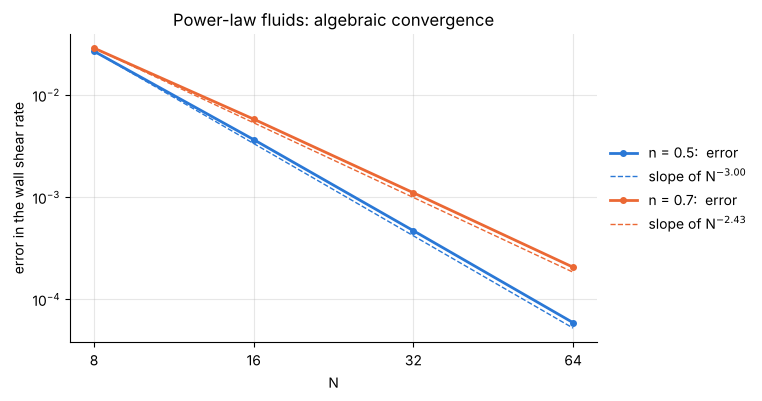

In [5]:
N_values = np.array([8, 16, 32, 64])
shear_errors = {}
print("   n     exact      N = 8      N = 16     N = 32     N = 64     order")
for n in (1.0, 0.5, 0.7):
    p = (n + 1) / n
    errors = []
    for N in N_values:
        D, y = cheb(N)
        errors.append(abs(-(D @ (1 - np.abs(y) ** p))[0] - p))          # row 0 is the wall y = +1
    shear_errors[n] = np.array(errors)
    order = f"{np.log2(errors[2] / errors[3]):6.2f}" if n != 1 else " exact"       # from the last doubling of N
    print(f"{n:5.1f} {p:8.4f}  " + "  ".join(f"{e:9.1e}" for e in errors) + "   " + order)

D_half, y_half = scale_cheb(8, 0.0, 1.0)                           # half channel 0 ≤ y ≤ 1; index 0 is the wall y = 1
half_channel_error = abs(-(D_half @ (1 - y_half**3))[0] - 3)
print(f"n = 0.5 on the half channel with N = 8: error {half_channel_error:.1e}")

fig, ax = plt.subplots(figsize=(6.8, 4))
for n in (0.5, 0.7):
    p = (n + 1) / n
    line, = ax.loglog(N_values, shear_errors[n], "o-", ms=4, label=f"n = {n}:  error")
    ax.loglog(N_values, shear_errors[n][0] * (N_values / 8.0) ** -p, "--", lw=1, color=line.get_color(), label=f"slope of N$^{{-{p:.2f}}}$")
ax.set(xlabel="N", ylabel="error in the wall shear rate", title="Power-law fluids: algebraic convergence",
       xticks=N_values, xticklabels=N_values)
ax.minorticks_off()
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [6]:
# verify: the Newtonian case is exact to rounding; the other two converge algebraically to the exact
# value (n + 1)/n, with the order (n + 1)/n measured between N = 32 and N = 64
assert shear_errors[1.0].max() < 1e-12
for n in (0.5, 0.7):
    local_order = np.log2(shear_errors[n][2] / shear_errors[n][3])
    assert abs(local_order - (n + 1) / n) < 0.05
    assert shear_errors[n][3] < 1e-3 and shear_errors[n][3] > 1e-6        # converging, but far from rounding level
assert half_channel_error < 1e-12

**Answer.** Only the Newtonian case $n = 1$ converges spectrally, and in fact it is exact
for every $N \ge 2$ (errors of $10^{-14}$ or less), because the profile $1 - y^2$ is a polynomial.
For $n = 1/2$ the error in the wall shear rate falls from $2.7\times10^{-2}$ at $N = 8$ to
$5.9\times10^{-5}$ at $N = 64$, with measured order 2.99; for $n = 0.7$ it falls from
$2.9\times10^{-2}$ to $2.1\times10^{-4}$, with measured order 2.42. Both are algebraic, with
an order close to the exponent $(n+1)/n$ of the profile, and 65 points give only four or five
digits. The cause is at the centre of the channel, not at the wall: $|y|^{(n+1)/n}$ is a polynomial only when
$(n+1)/n$ is an even integer, and otherwise one of its derivatives jumps or is unbounded at
$y = 0$. Using the symmetry helps when the exponent is an integer: on the half channel
$0 \le y \le 1$ the profile for $n = 1/2$ is the cubic $1 - y^3$, and 9 points give the wall
shear rate to rounding level (the last line of the output). For $n = 0.7$ the singularity
remains, at the end $y = 0$ of the half channel.

## Exercise 3

Repeat the geometric-rate check of 5.4 for $f(x) = 1/(1 + 25x^2)$. Predict $\rho$ first.

**Prediction.** The poles are at $x = \pm i/5$, at the ends of the minor axis of the Bernstein
ellipse, so $b = \tfrac15$ and $\rho = b + \sqrt{1 + b^2} = (1 + \sqrt{26})/5 = 1.2198$. The
rate is much lower than the 1.618 of 5.4, so the fit needs a longer range of $N$: the error
reaches rounding level only beyond $N = 160$. As in 5.4 the factor $N$ is divided out before
fitting.

measured ρ = 1.2197   theory = 1.2198


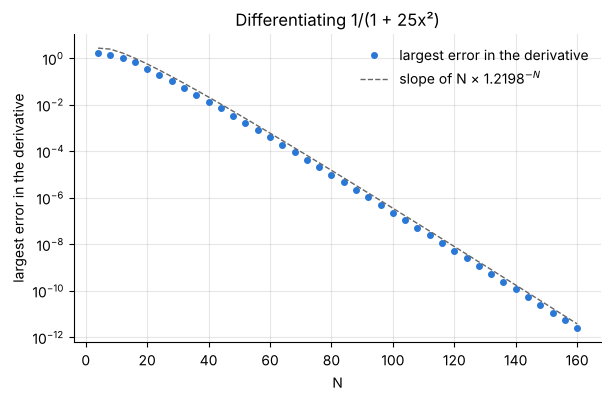

In [7]:
f = lambda x: 1 / (1 + 25 * x**2)
df = lambda x: -50 * x / (1 + 25 * x**2) ** 2

N_values = np.arange(4, 161, 4)
errors = np.array([np.abs(cheb(N)[0] @ f(cheb(N)[1]) - df(cheb(N)[1])).max() for N in N_values])
window = (N_values >= 40) & (N_values <= 160)
rho_measured = np.exp(-np.polyfit(N_values[window], np.log(errors[window] / N_values[window]), 1)[0])
rho_theory = (1 + np.sqrt(26)) / 5
print(f"measured ρ = {rho_measured:.4f}   theory = {rho_theory:.4f}")

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.semilogy(N_values, errors, "o", ms=4, label="largest error in the derivative")
ax.semilogy(N_values, 1.5 * N_values * rho_theory ** (-N_values.astype(float)), "--", color="0.4", lw=1, label=f"slope of N × {rho_theory:.4f}$^{{-N}}$")
ax.set(xlabel="N", ylabel="largest error in the derivative", title="Differentiating 1/(1 + 25x²)")
ax.legend(frameon=False, loc="upper right");

In [8]:
# verify: the measured rate against the Bernstein ellipse prediction
assert abs(rho_measured / rho_theory - 1) < 2e-3

**Answer.** The predicted rate is $\rho = (1 + \sqrt{26})/5 = 1.2198$ and the measured
rate, fitted over $40 \le N \le 160$ with the factor $N$ divided out, is 1.2197. The narrower
peak brings the poles closer to the interval than those of $1/(1 + 4x^2)$, and the cost is
plain: one more digit needs $\log 10/\log\rho \approx 12$ more points, where the wider peak
of 5.4 needed 5.

## Exercise 4

Map the Chebyshev points to $[0, 5]$ and differentiate $u(x) = e^{-x}\sin(4x)$. How many
points are needed for an error below $10^{-8}$ in $u'$? Repeat on $[0, 20]$ and compare.

`scale_cheb(N, 0, L)` supplies the mapped points and the matrix scaled by $2/L$. The exact
derivative is $u' = e^{-x}(4\cos 4x - \sin 4x)$. Increase $N$ until the largest error falls below
the target. The longer interval holds four times as many oscillations, so expect to need more
points, though not four times as many: once there are about $\pi$ points per wavelength the
convergence is so fast that the extra points needed to reach the target hardly depend on the
length. To see how much the factor $e^{-x}$ matters, the count is repeated for the undamped
$\sin 4x$.

[0, 5]: error below 1e-8 from N = 26 (27 points), error there 4.9e-09, 3.2 wavelengths, 8.2 points per wavelength
[0, 20]: error below 1e-8 from N = 58 (59 points), error there 8.5e-09, 12.7 wavelengths, 4.6 points per wavelength
[0, 5]: undamped sin(4x) needs N = 27;  π points per wavelength is N = 10;  margin beyond it: 16 with the factor exp(−x), 17 without
[0, 20]: undamped sin(4x) needs N = 66;  π points per wavelength is N = 40;  margin beyond it: 18 with the factor exp(−x), 26 without


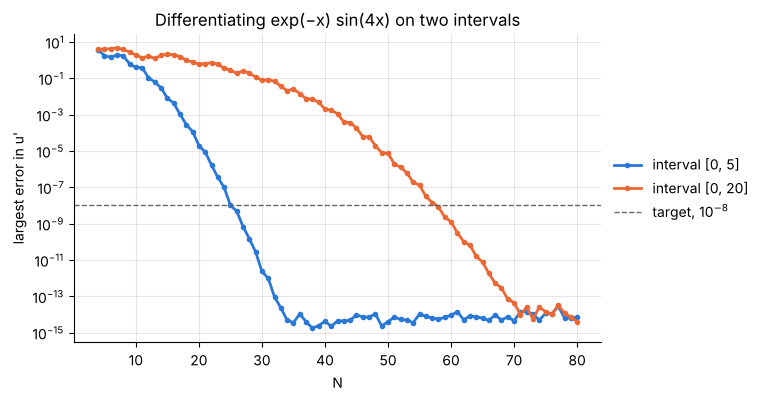

In [9]:
u = lambda x: np.exp(-x) * np.sin(4 * x)
du = lambda x: np.exp(-x) * (4 * np.cos(4 * x) - np.sin(4 * x))

def derivative_error(N, length):
    D, x = scale_cheb(N, 0.0, length)
    return np.abs(D @ u(x) - du(x)).max()

N_values = np.arange(4, 81)
errors, needed = {}, {}
for length in (5.0, 20.0):
    errors[length] = np.array([derivative_error(N, length) for N in N_values])
    needed[length] = N_values[errors[length] < 1e-8][0]
    print(f"[0, {length:.0f}]: error below 1e-8 from N = {needed[length]} ({needed[length] + 1} points), "
          f"error there {errors[length][N_values == needed[length]][0]:.1e}, "
          f"{4 * length / (2 * np.pi):.1f} wavelengths, {needed[length] / (4 * length / (2 * np.pi)):.1f} points per wavelength")

# the same count for the undamped sin(4x), and the margin over π points per wavelength (N = 4 × length / 2)
needed_undamped = {}
for length in (5.0, 20.0):
    for N in N_values:
        D, x = scale_cheb(N, 0.0, length)
        if np.abs(D @ np.sin(4 * x) - 4 * np.cos(4 * x)).max() < 1e-8:
            needed_undamped[length] = N
            break
    threshold = 4 * length / 2                                       # π points per wavelength: N = π × 4 × length / (2π)
    print(f"[0, {length:.0f}]: undamped sin(4x) needs N = {needed_undamped[length]};  π points per wavelength is N = {threshold:.0f};  "
          f"margin beyond it: {needed[length] - threshold:.0f} with the factor exp(−x), {needed_undamped[length] - threshold:.0f} without")

fig, ax = plt.subplots(figsize=(6.8, 4))
for length in (5.0, 20.0):
    ax.semilogy(N_values, errors[length], "o-", ms=3, label=f"interval [0, {length:.0f}]")
ax.axhline(1e-8, color="0.4", lw=1, ls="--", label="target, 10$^{-8}$")
ax.set(xlabel="N", ylabel="largest error in u'", title="Differentiating exp(−x) sin(4x) on two intervals")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [10]:
# verify: the errors are measured against the exact derivative; the counts found are the first N below
# the target, the error stays below it afterwards, and the longer interval needs more points but fewer than four times as many
for length in (5.0, 20.0):
    assert derivative_error(needed[length], length) < 1e-8 <= derivative_error(needed[length] - 1, length)
    assert errors[length][N_values >= needed[length]].max() < 1e-8
assert needed[5.0] < needed[20.0] < 4 * needed[5.0]
assert needed_undamped[20.0] < 3 * needed_undamped[5.0]               # without the decay the long interval is still far cheaper than four times

**Answer.** On $[0, 5]$ the error in $u'$ is below $10^{-8}$ from $N = 26$ (27 points); on
$[0, 20]$ from $N = 58$ (59 points). An interval four times as long needs 2.2 times as many
points. Both curves show the same pattern: almost no accuracy until there are about $\pi$
points per wavelength of $\sin 4x$ on average ($N \approx 10$ and $N \approx 40$), then
rapid convergence. The long interval is cheaper per wavelength (4.6 points against 8.2). The
decay is not the main reason: for the undamped $\sin 4x$ the counts are $N = 27$ and $N = 66$,
still only 2.4 times as many. A polynomial needs about $\pi$ points per wavelength before it
converges at all, and the further margin needed to reach the target hardly grows with the
length of the interval (16 more on $[0, 5]$, 18 more on $[0, 20]$). The factor $e^{-x}$ lowers
the count on the long interval a little further, from 66 to 58. The lesson for practice: scale the computational
interval to the region where the solution is active, since every extra wavelength inside it
costs points.

## Exercise 5

Plot the minimum spacing of the Chebyshev grid against $N$ on logarithmic axes and confirm
that it scales as $N^{-2}$. What does this imply for the number of points needed to resolve
a thin boundary layer at a wall, compared with an equally spaced grid?

The smallest gap of the Chebyshev grid is the first one, $x_0 - x_1 = 1 - \cos(\pi/N)$, which
for large $N$ is $\pi^2/(2N^2)$. An equally spaced grid with the same number of points has the
gap $2/N$ everywhere.

fitted slope for N ≥ 16: -1.9995
N = 1000: smallest gap 4.9348e-06,  π²/(2N²) = 4.9348e-06


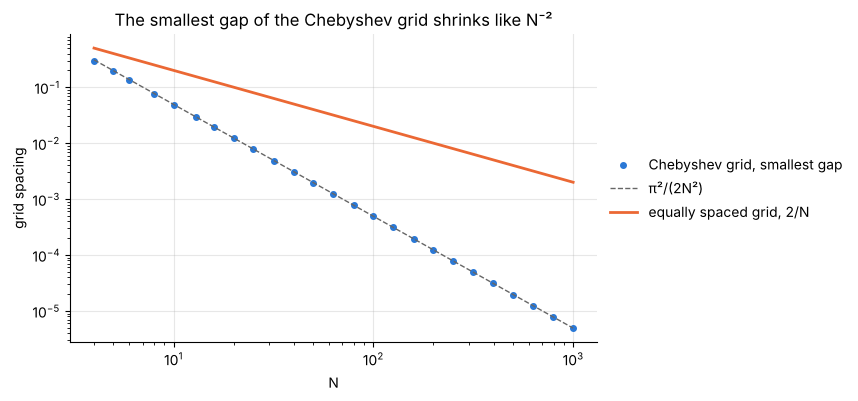

In [11]:
N_values = np.unique(np.round(np.geomspace(4, 1000, 25)).astype(int))
min_spacing = np.array([np.abs(np.diff(cheb(N)[1])).min() for N in N_values])
slope = np.polyfit(np.log(N_values[N_values >= 16]), np.log(min_spacing[N_values >= 16]), 1)[0]
print(f"fitted slope for N ≥ 16: {slope:.4f}")
print(f"N = 1000: smallest gap {min_spacing[-1]:.4e},  π²/(2N²) = {np.pi**2 / (2 * 1000**2):.4e}")

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.loglog(N_values, min_spacing, "o", ms=4, label="Chebyshev grid, smallest gap")
ax.loglog(N_values, np.pi**2 / (2.0 * N_values**2), "--", color="0.4", lw=1, label="π²/(2N²)")
ax.loglog(N_values, 2 / N_values, label="equally spaced grid, 2/N")
ax.set(xlabel="N", ylabel="grid spacing", title="The smallest gap of the Chebyshev grid shrinks like N⁻²")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

For the boundary layer, ask how large $N$ must be to place 5 grid points (not counting the
wall point itself) inside a layer of thickness $\delta$ at the wall $x = 1$. The point $x_j$ is
inside the layer when $1 - \cos(j\pi/N) \le \delta$, which for a thin layer is
$j \le N\sqrt{2\delta}/\pi$. So the Chebyshev grid needs $N \approx 5\pi/\sqrt{2\delta}$ and
the equally spaced grid, with gap $2/N$, needs $N = 10/\delta$.

In [12]:
def points_in_layer(x, thickness):
    return np.count_nonzero((x < 1) & (x >= 1 - thickness))

print("    δ      N, Chebyshev    5π/√(2δ)    N, equally spaced")
layer_counts = {}
for thickness in (1e-1, 1e-2, 1e-3):
    N_cheb = next(N for N in range(2, 5000) if points_in_layer(cheb(N)[1], thickness) >= 5)
    N_equi = int(np.ceil(10 / thickness))
    layer_counts[thickness] = (N_cheb, N_equi)
    print(f"{thickness:7.0e} {N_cheb:10d} {5 * np.pi / np.sqrt(2 * thickness):14.1f} {N_equi:14d}")

    δ      N, Chebyshev    5π/√(2δ)    N, equally spaced
  1e-01         35           35.1            100
  1e-02        111          111.1           1000
  1e-03        352          351.2          10000


In [13]:
# verify: the slope against −2, the gap against the exact 1 − cos(π/N) and its large-N form π²/(2N²),
# and the counted N for the layer against the estimate 5π/√(2δ)
assert abs(slope + 2) < 0.01
assert np.allclose(min_spacing, 1 - np.cos(np.pi / N_values), rtol=1e-9)
assert abs(min_spacing[-1] / (np.pi**2 / (2 * 1000**2)) - 1) < 1e-5
for thickness, (N_cheb, N_equi) in layer_counts.items():
    assert abs(N_cheb / (5 * np.pi / np.sqrt(2 * thickness)) - 1) < 0.01

**Answer.** The smallest gap is $1 - \cos(\pi/N)$, the fitted slope on logarithmic axes
is $-1.9995$, and at $N = 1000$ the gap is $4.93\times10^{-6}$, equal to $\pi^2/(2N^2)$ to five
digits. So the Chebyshev grid resolves a layer of thickness $\delta$ at a wall with a number
of points proportional to $\delta^{-1/2}$, where an equally spaced grid needs a number
proportional to $\delta^{-1}$. To put 5 points inside the layer takes $N = 35$, 111 and 352 for
$\delta = 10^{-1}$, $10^{-2}$ and $10^{-3}$ on the Chebyshev grid, against 100, 1000 and
10000 equally spaced points. The thinner the layer, the larger the advantage. The price is the
one met in 5.6: tiny gaps mean large entries in $D$ and larger rounding errors.